In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

In [3]:
top_hvg = hdata.get_highly_variable_genes(n=2000)

In [4]:
cells_hvg = hdata.get_timepoint_cells(n=100)     # 100 x 6tp = 600 cells

In [5]:
# Initialize a temporary subset object for the selected cells 
subset_cells_ = hdata[top_hvg, cells_hvg]    # 2000 genes x 600 cells

# Cell

## Total RNA

### PCA-based clusters 

gene x cell expression matrix -> PCA (cell x PC) -> distance matrix -> cluster

In [6]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=20
)

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

sim_pca_cells_ = hdata.similarities["correlation_pca_cell_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim_pca_cells_,
    kind="cell",
    k=6
)

cl_pca_cells_ = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id="pc20"
)

em_pca_cells_ = hdata.embeddings["umap_cell_pc20"]

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc20" stored! 



#### Original

In [ ]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_pca_cells_,
    embedding=em_pca_cells_,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

#### Test

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

In [ ]:
def plot_scatter(
    embedding: tuple = None,
    cluster: pd.Series = None,
    highlight: object = None,
    values: pd.Series = None,
    mask: pd.Series = None,
    title: str = None,
    show_label: bool = False,
    legend_label: str = None
    ) -> None:
    """Flexible scatter plot on a fixed UMAP embedding. Supports four modes,
       chosen by which arguments are given:

        1. cluster only                -> all clusters, each its own color
                                           (equivalent to the old plot_scatter)
        2. cluster + highlight         -> only that cluster colored, rest grey
        3. values only                 -> continuous color across ALL cells
        4. mask only                   -> discrete highlight: masked cells
                                           colored, rest grey (e.g. timepoint)
        5. values + mask               -> continuous color restricted to
                                           masked cells, rest grey

    """
    if cluster is None and values is None and mask is None:
        raise ValueError("Provide at least one of `cluster`, `values`, or `mask`.")

    coords, xlabel, ylabel = embedding
    fig, ax = plt.subplots(figsize=(8, 6))
    cmap = "RdYlBu"

    # ---- Mode 1: cluster given, no highlight -> all clusters, own colors ----
    if cluster is not None and highlight is None:
        cell_names = cluster.index.tolist()
        cluster_labels = cluster.values

        cmap_cluster = plt.get_cmap("Paired")
        norm = mpl.colors.Normalize(vmin=0, vmax=9)
        unique_labels = sorted(set(cluster_labels))
        color_map = {label: cmap_cluster(norm(label)) for label in unique_labels}

        for label in unique_labels:
            m = cluster_labels == label
            ax.scatter(
                coords[m, 0], coords[m, 1],
                color=color_map[label],
                label=str(label)
            )

        ax.legend(
            title="Cluster",
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            borderaxespad=0,
            frameon=True
        )

    else:
        # ---- Modes 2-5: single highlighted group, rest grey ----
        highlight_color = None

        if cluster is not None:
            # Mode 2: cluster + highlight -> convert to mask + fixed color
            unique_labels = sorted(set(cluster.values))
            if highlight not in unique_labels:
                raise ValueError(
                    f"highlight={highlight!r} not found in cluster labels {unique_labels}"
                )

            cmap_cluster = plt.get_cmap("Paired")
            norm = mpl.colors.Normalize(vmin=0, vmax=9)
            highlight_color = cmap_cluster(norm(highlight))

            cluster_mask = cluster == highlight
            mask = cluster_mask if mask is None else (mask.reindex(cluster.index) & cluster_mask)

            if legend_label is None:
                legend_label = f"cluster {highlight}"

        ref = values if values is not None else (mask if mask is not None else cluster)
        cell_names = ref.index.tolist()

        if values is not None and mask is not None:
            mask = mask.reindex(values.index)

        if values is not None and mask is None:
            # Mode 3: continuous color across all cells
            sc = ax.scatter(coords[:, 0], coords[:, 1], c=values.values, cmap=cmap, zorder=2)
            cbar = fig.colorbar(sc, ax=ax)
            cbar.set_label(legend_label or values.name or "value")

        elif mask is not None and values is None:
            # Mode 2/4: discrete highlight
            mask_vals = mask.values.astype(bool)
            color = highlight_color if highlight_color is not None else "tab:red"

            ax.scatter(coords[~mask_vals, 0], coords[~mask_vals, 1], color="lightgrey", label="_nolegend_", zorder=1)
            ax.scatter(coords[mask_vals, 0], coords[mask_vals, 1], color=color, label=legend_label or "highlighted", zorder=2)
            ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, frameon=True)

        else:
            # Mode 5: continuous restricted to masked cells
            mask_vals = mask.values.astype(bool)

            ax.scatter(coords[~mask_vals, 0], coords[~mask_vals, 1], color="lightgrey", label="_nolegend_", zorder=1)
            sc = ax.scatter(coords[mask_vals, 0], coords[mask_vals, 1], c=values.values[mask_vals], cmap=cmap, zorder=2)
            cbar = fig.colorbar(sc, ax=ax)
            cbar.set_label(legend_label or values.name or "value")

    if show_label:
        for i, name in enumerate(cell_names):
            ax.annotate(name, coords[i], fontsize=7, ha="left")

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    plt.tight_layout()
    plt.show()

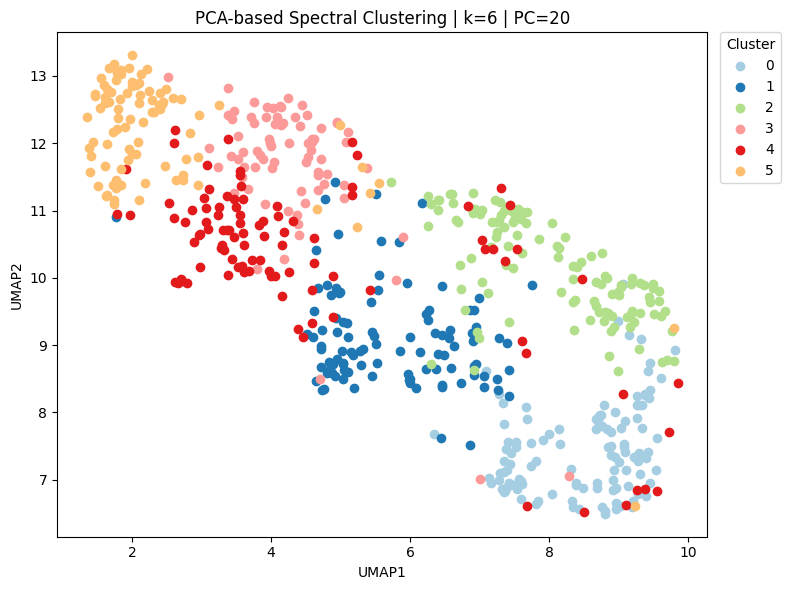

In [ ]:
# all clusters

plot_scatter(
    embedding=em_pca_cells_, 
    cluster=cl_pca_cells_,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    )

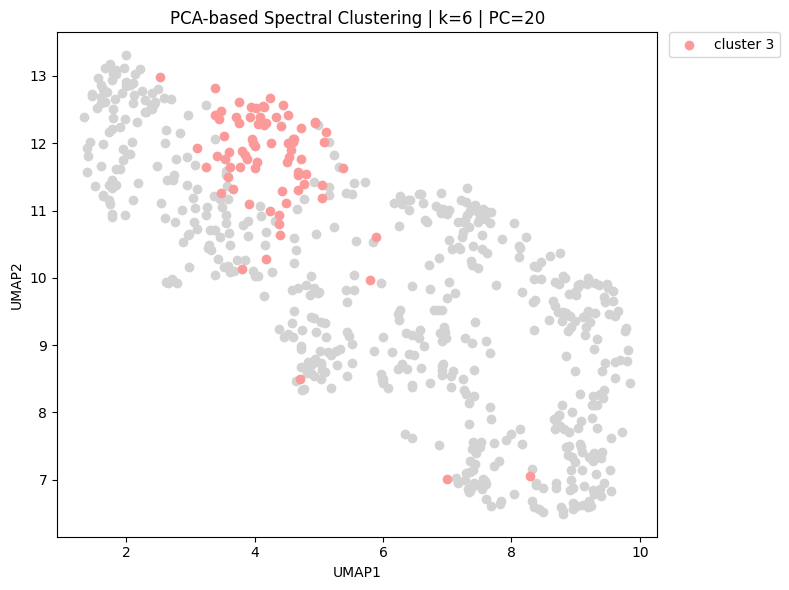

In [ ]:
# specific cluster

plot_scatter(
    embedding=em_pca_cells_, 
    cluster=cl_pca_cells_,
    highlight=3,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    )

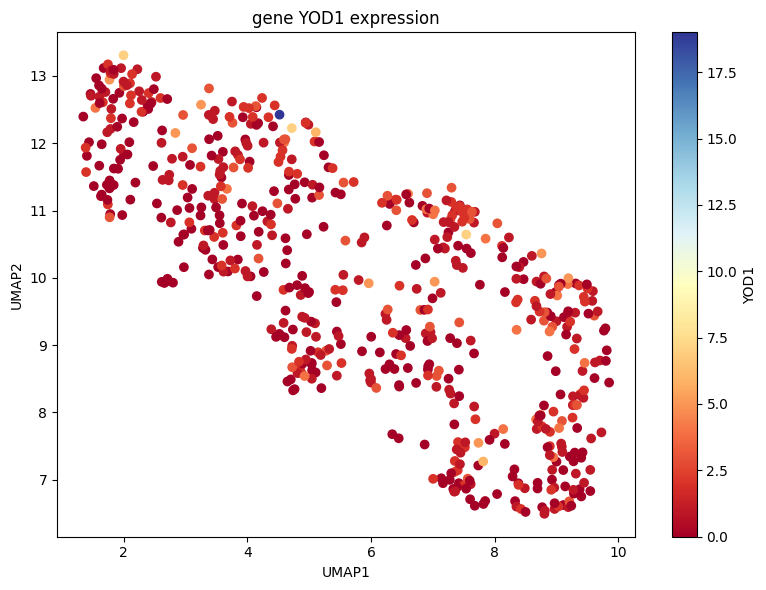

In [ ]:
# gene name alone -> continuous, all cells

g1 = subset_cells_.get_gene_expression('YOD1')
plot_scatter(
    embedding=em_pca_cells_, 
    values=g1, 
    legend_label="YOD1",
    title="gene YOD1 expression",
    )

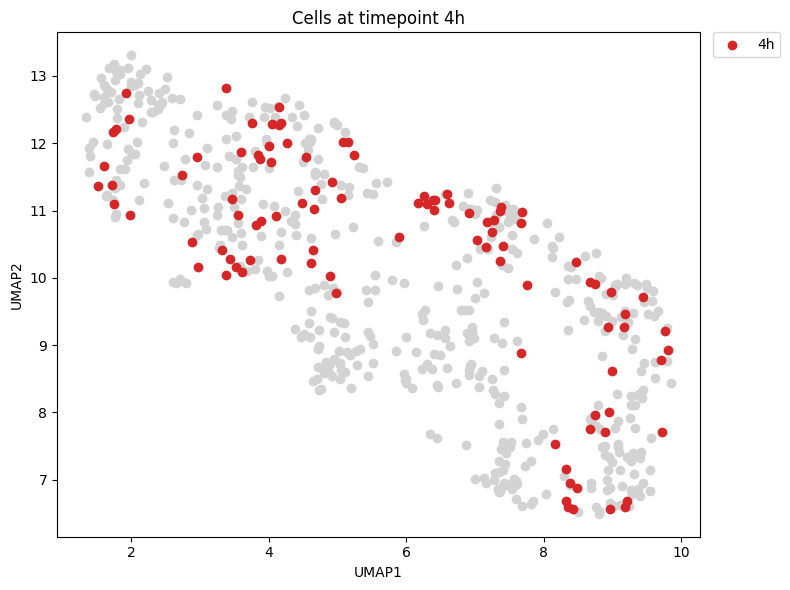

In [ ]:
# timepoint alone -> discrete highlight

time_mask = subset_cells_.obs["time"] == "4h" 
plot_scatter(
    embedding=em_pca_cells_, 
    mask=time_mask, 
    legend_label="4h",
    title="Cells at timepoint 4h",
    )

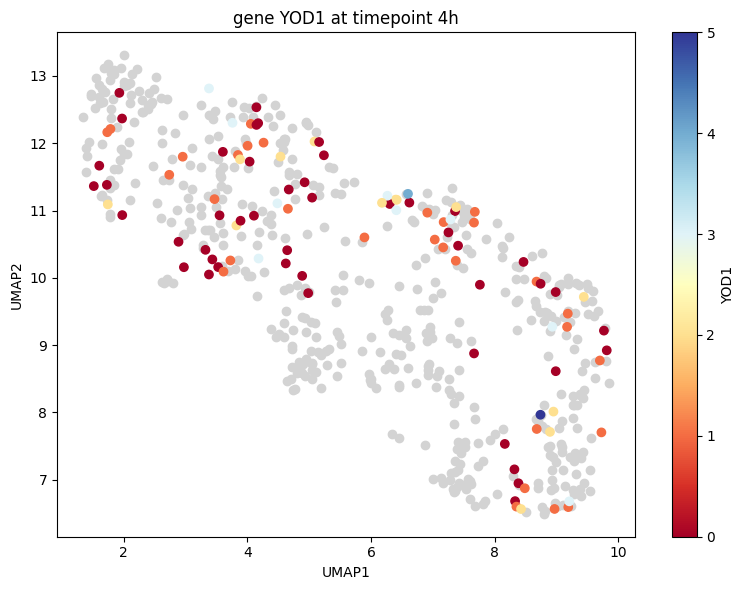

In [ ]:
# gene + timepoint -> continuous, restricted to timepoint
plot_scatter(
    embedding=em_pca_cells_, 
    values=g1, 
    mask=time_mask, 
    legend_label="YOD1",
    title="gene YOD1 at timepoint 4h",
    )